# 02 — EDA: demand, regions, departments

Reads the single tidy file from notebook 01 and answers:
- how does network demand move over time (trend + seasonality)?
- which **regions** dominate, and how big is each of the 35 trusts (non-IID evidence)?
- which **departments** (specialties) dominate — overall and per region?
- how has the **backlog** (waiting list) evolved?

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

df = pd.read_csv("../data/processed/rtt_long.csv")

# region of each trust, from the config
net = json.load(open("../config/nhs_network.json"))
region_of = {t["code"]: r["region"] for r in net["regions"] for t in r["trusts"]}
df["region"] = df["provider_code"].map(region_of)
df["specialty"] = df["specialty_name"].str.replace(" Service", "", regex=False)

p3 = df[df["part"] == "Part_3"]   # demand  (new referrals; count = total_all)
p2 = df[df["part"] == "Part_2"]   # backlog (waiting list;  count = total_all, bands = ageing)

# chart style (one place)
BLUE = "#2a78d6"
REGION_COLORS = {  # fixed categorical order - never reassigned
    "East of England": "#2a78d6", "London": "#eb6834", "Midlands": "#1baf7a",
    "North East and Yorkshire": "#eda100", "North West": "#e87ba4",
    "South East": "#008300", "South West": "#4a3aa7",
}
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#3987e5", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
})

print(f"months: {p3['month'].nunique()} | trusts: {p3['provider_code'].nunique()} "
      f"| specialties (departments): {p3['specialty'].nunique()} | regions: {p3['region'].nunique()}")

months: 60 | trusts: 35 | specialties (departments): 23 | regions: 7


## Network demand over time — trend and seasonality

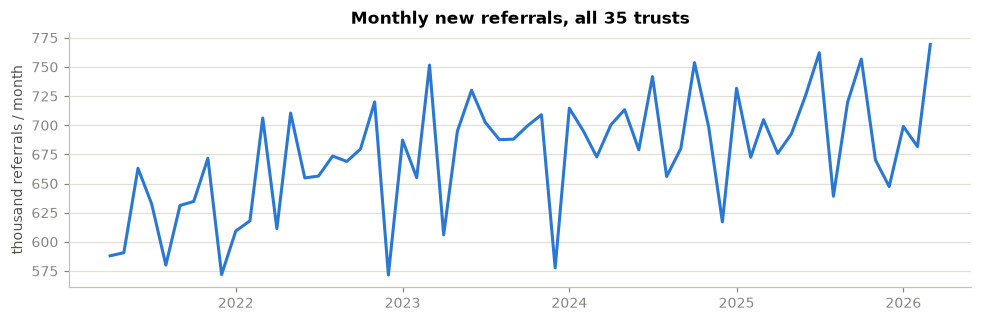

In [2]:
monthly = p3.groupby("month")["total_all"].sum()
x = pd.to_datetime(monthly.index)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(x, monthly / 1000, color=BLUE, linewidth=2)
ax.set_title("Monthly new referrals, all 35 trusts")
ax.set_ylabel("thousand referrals / month")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

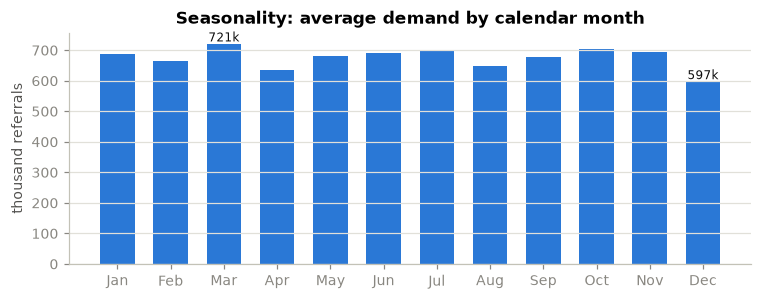

In [3]:
# average demand by calendar month: December trough, March peak
moy = monthly.groupby(monthly.index.str[5:7]).mean() / 1000
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(labels, moy.values, color=BLUE, width=0.65)
for i in [2, 11]:  # direct-label only the peak (Mar) and the trough (Dec)
    ax.text(i, moy.values[i] + 8, f"{moy.values[i]:.0f}k", ha="center", color="#0b0b0b", fontsize=8)
ax.set_title("Seasonality: average demand by calendar month")
ax.set_ylabel("thousand referrals")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## Which regions dominate, and how big is each trust (non-IID evidence)

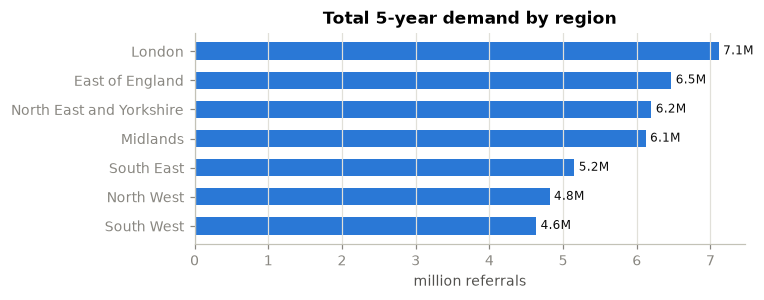

In [4]:
reg = p3.groupby("region")["total_all"].sum().sort_values() / 1e6

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(reg.index, reg.values, color=BLUE, height=0.6)
for i, v in enumerate(reg.values):
    ax.text(v + 0.06, i, f"{v:.1f}M", va="center", color="#0b0b0b", fontsize=8)
ax.set_title("Total 5-year demand by region")
ax.set_xlabel("million referrals")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

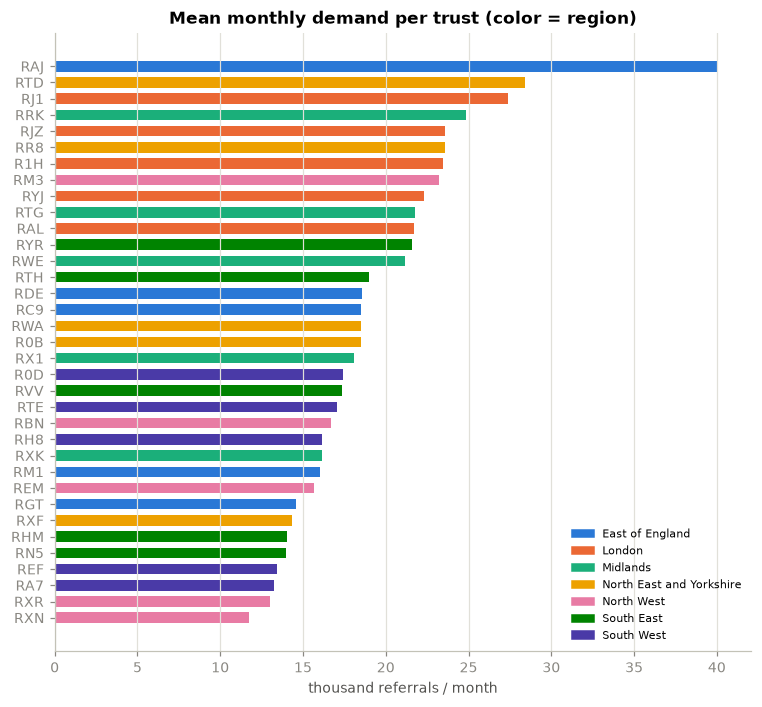

largest / smallest trust: 40.1k / 11.7k = 3.4x spread


In [5]:
# every trust's average monthly demand, colored by its region -> ~3.4x scale spread = non-IID
trust = (p3.groupby(["provider_code", "region"])["total_all"].sum() / p3["month"].nunique()) / 1000
trust = trust.reset_index(name="mean_ref").sort_values("mean_ref")

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(trust["provider_code"], trust["mean_ref"],
        color=[REGION_COLORS[r] for r in trust["region"]], height=0.65)
ax.set_title("Mean monthly demand per trust (color = region)")
ax.set_xlabel("thousand referrals / month")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in REGION_COLORS.values()],
          labels=list(REGION_COLORS), loc="lower right", fontsize=7, frameon=False)
plt.tight_layout()
plt.show()
print(f"largest / smallest trust: {trust['mean_ref'].max():.1f}k / {trust['mean_ref'].min():.1f}k "
      f"= {trust['mean_ref'].max() / trust['mean_ref'].min():.1f}x spread")

## Which departments dominate — overall and per region

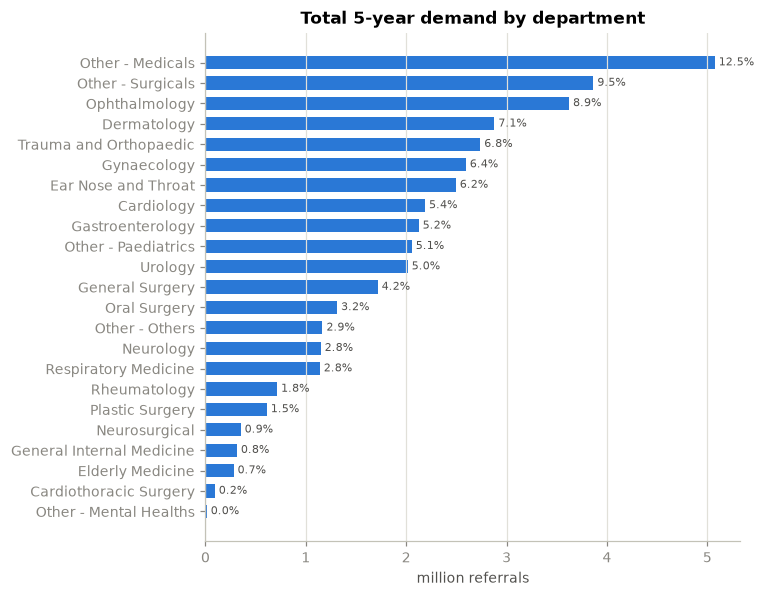

In [6]:
spec = p3.groupby("specialty")["total_all"].sum().sort_values()
share = 100 * spec / spec.sum()

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(spec.index, spec.values / 1e6, color=BLUE, height=0.65)
for i, (v, s) in enumerate(zip(spec.values / 1e6, share.values)):
    ax.text(v + 0.04, i, f"{s:.1f}%", va="center", color="#52514e", fontsize=7)
ax.set_title("Total 5-year demand by department")
ax.set_xlabel("million referrals")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

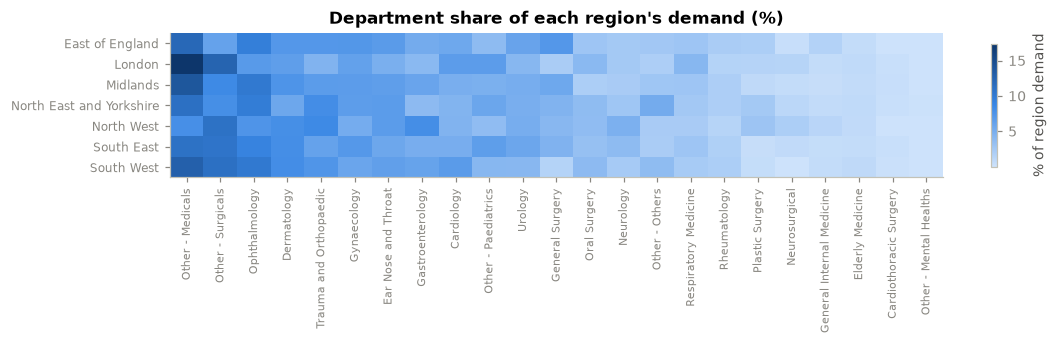

In [7]:
# demand mix per region: each row = a region, cells = % of that region's demand per department
mix = p3.groupby(["region", "specialty"])["total_all"].sum().unstack(fill_value=0)
mix = 100 * mix.div(mix.sum(axis=1), axis=0)
mix = mix[mix.mean().sort_values(ascending=False).index]  # biggest departments first

fig, ax = plt.subplots(figsize=(10.5, 3.2))
im = ax.imshow(mix.values, cmap=BLUES, aspect="auto")
ax.set_xticks(range(mix.shape[1]), mix.columns, rotation=90, fontsize=7)
ax.set_yticks(range(mix.shape[0]), mix.index, fontsize=8)
ax.set_title("Department share of each region's demand (%)")
ax.grid(visible=False)
fig.colorbar(im, ax=ax, label="% of region demand", shrink=0.85)
plt.tight_layout()
plt.show()

## Backlog: waiting list size and how bad the waiting is

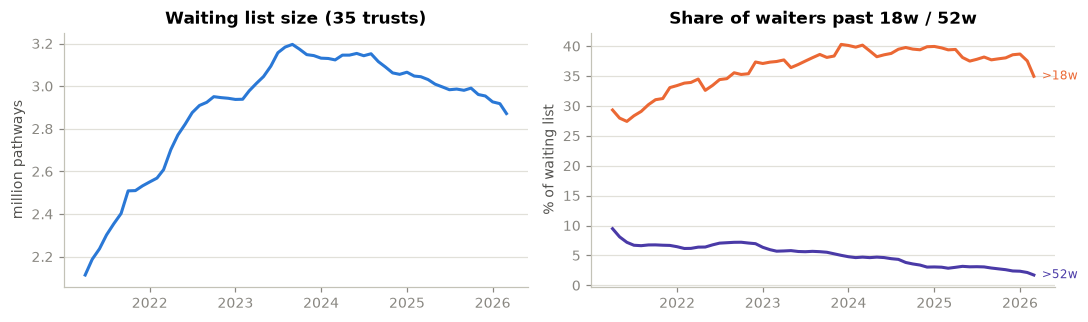

In [8]:
bk = p2.groupby("month")[["total_all", "weeks_0_18", "weeks_18_52", "weeks_52_plus"]].sum()
banded = bk[["weeks_0_18", "weeks_18_52", "weeks_52_plus"]].sum(axis=1)
x = pd.to_datetime(bk.index)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.plot(x, bk["total_all"] / 1e6, color=BLUE, linewidth=2)
ax1.set_title("Waiting list size (35 trusts)")
ax1.set_ylabel("million pathways")
ax1.grid(axis="x", visible=False)

ax2.plot(x, 100 * bk["weeks_18_52"] / banded, color="#eb6834", linewidth=2)
ax2.plot(x, 100 * bk["weeks_52_plus"] / banded, color="#4a3aa7", linewidth=2)
ax2.text(x[-1], (100 * bk["weeks_18_52"] / banded).iloc[-1], "  >18w", color="#eb6834", va="center", fontsize=8)
ax2.text(x[-1], (100 * bk["weeks_52_plus"] / banded).iloc[-1], "  >52w", color="#4a3aa7", va="center", fontsize=8)
ax2.set_title("Share of waiters past 18w / 52w")
ax2.set_ylabel("% of waiting list")
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Takeaways**
- Demand trends up over the 5 years with clear seasonality (December trough, March peak, ~21% swing) — signal a forecaster must learn.
- Trust sizes spread ~3.4x and regions differ in department mix — the **non-IID** heterogeneity that motivates FedProx/adaptive aggregation.
- T&O and Ophthalmology are the biggest departments overall; the mix varies by region.
- The backlog panel (right) is what the agentic plane will monitor: demand forecast + throughput → projected >18w / >52w shares.